# Exploración de factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

# 🧩 Carga y exploración del dataset

**🎯 Objetivo:**

Tener el dataset cargado en la memoria y realizar una revisión preliminar 

In [1]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, pointbiserialr

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


# Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head(5)

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


# Preparación de datos y supuestos

**Exploración inicial de los datos**

El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` es de tipo `float64`, pero al representar años cumplidos, debe ser convertida a número entero (`int`).


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype(int)

In [5]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


# Exploración de variables numéricas

In [6]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


**Diagnóstico inicial de variables numéricas:**

- `edad`— Rango de edades: El cliente más joven tiene 18 años y el mayor tiene 75 años. El promedio se sitúa a los **38.26 años**.


- `nivel_ingreso` — El ingreso anual estimado promedio es de **30,019.70**, con un rango que va desde '8000' hasta un máximo de **74,790.84**.


- `visitas_mes` — En promedio, los usuarios visitan la plataforma **10.03** veces al mes, aunque hay clientes muy activos con hasta 25.00 visitas.


- `compras_mes` — El 75% de los usuarios realiza **2 compras al mes** con un máximo de 8 compras registradas.


- `gasto_publicidad_dirigida` — El gasto promedio por usuario es de **20.15**.


- `satisfaccion` — La calificación promedio es de **3.60**, y el valor mínimo registrado es 1 (lo que indica que si hay usuarios calificando con el valor más bajo).


- `ingreso_anual` — El ingreso promedio generado para la empresa por usuario es de **36.59**.

# Exploración de variables binarias

In [7]:
# Verificar que cada columna tenga únicamente dos valores posibles
print("Miembro Premium")
print(df['miembro_premium'].value_counts())
print("\nAbandono:")
print(df['abandono'].value_counts())

Miembro Premium
0    12911
1     2089
Name: miembro_premium, dtype: int64

Abandono:
0    12739
1     2261
Name: abandono, dtype: int64


**Diagnóstico inicial de variables binarias:**

- `miembro_premium`— La gran mayoría de los clientes no tienen **suscripción premium** (12,911), mientras que solo 2,089, si lo son (valor 1). 


- `abandono` — Un total de 2,261 clientes **abandonaron la plataforma** (valor 1), mientras que los 12,739 restantes, se mantuvieron activos.

# Exploración de variables categóricas

In [8]:
# Verificar el número de valores únicos por variable categórica
print("Valores únicos de dispositivo:", df['tipo_dispositivo'].nunique())
print("Valores únicos de región:", df['region'].nunique())

Valores únicos de dispositivo: 3
Valores únicos de región: 4


In [9]:
# Explorar variables categóricas y cómo se distribuyen
print("Distribución por Dispositivo:")
print(df['tipo_dispositivo'].value_counts())
print("\nDistribución por Región:")
print(df['region'].value_counts())

Distribución por Dispositivo:
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64

Distribución por Región:
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64


**Diagnóstico inicial de variables categóricas:**

- `tipo_dispositivo` — Los tipos de dispositivos que existen son: `móvil`, `escritorio` y `tablet`, siendo el **`móvil`** el que más se distribuye. 


- `region` — Las regiones en las que se distribuye son: `norte`, `oeste`, `sur` y `este`, en la cual el **`norte`** es la región en la que se concentra la mayor cantidad de usuarios.

# Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

# Visualización de relaciones

**🎯 Objetivo:** 

Identificar visualmente la fuerza, dirección y dispersión de las relaciones entre las variables numéricas, utilizando un mapa de calor global y gráficos de dispersión enfocados en los factores más asociados al "ingreso_anual".

## **Heatmap**

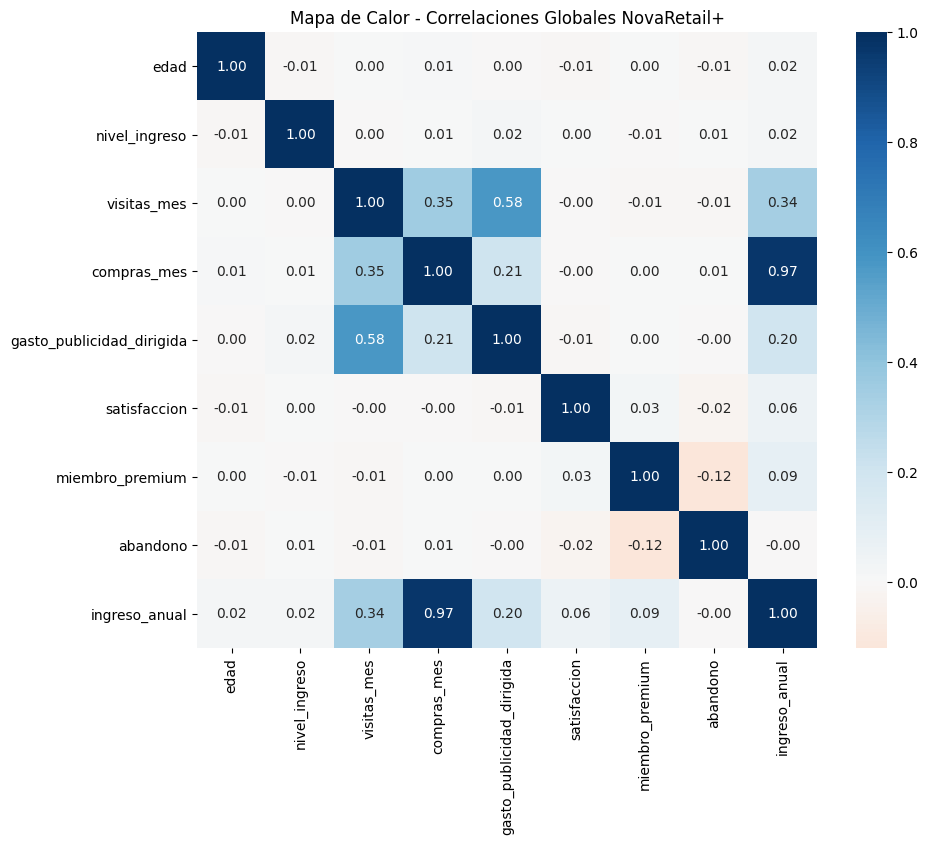

In [19]:
# Visualizar la matriz de correlación para identificar relaciones
plt.figure(figsize=(10, 8))

# Calculamos la correlación solo para variables numéricas
matriz_corr = df.select_dtypes(include='number').corr()

# Generamos el heatmap
sns.heatmap(data=matriz_corr, annot=True, cmap="RdBu", center=0, fmt=".2f")

plt.title("Mapa de Calor - Correlaciones Globales NovaRetail+")
plt.show()

**Observaciones generales (Heatmap):**

- Se observa que la gran mayoría de las variables tienen colores muy tenues (Cercanos a 0), lo que indica que no hay relaciones lineales fuertes entre la mayoría de los datos, sin embargo, destaca una correlación positiva moderada de 0.58 entre el `gasto_publicidad_dirigida` y las `visitas_mes`.

**Observaciones respecto a `ingreso_anual`:**  

- Presenta una correlación positiva muy alta de 0.97 con `compras_mes`, esto es un fuerte indicador de que a mayor cantidad de compras, el ingreso se dispara de forma proporcional (Alerta de colinealidad).


- Presenta relaciones positivas moderadas-débiles con `visitas_mes` de 0.34 y `gasto_publicidad_dirigida` de 0.20 y variables como `nivel_ingreso` con 0.02 y `satisfaccion` con 0.06, muestran correlación lineal prácticamente nula con el ingreso que genera el cliente para la empresa.

## Scatterplot general

Un Pairplot con 15,000 registros y múltiples variables numéricas, satura visualmente la información y consume demasiados recursos, es más funcional construir scatterplots individuales solo para las relaciones que mostraron "relevancia" en el heatmap.

**Scatterplot para pares clave**

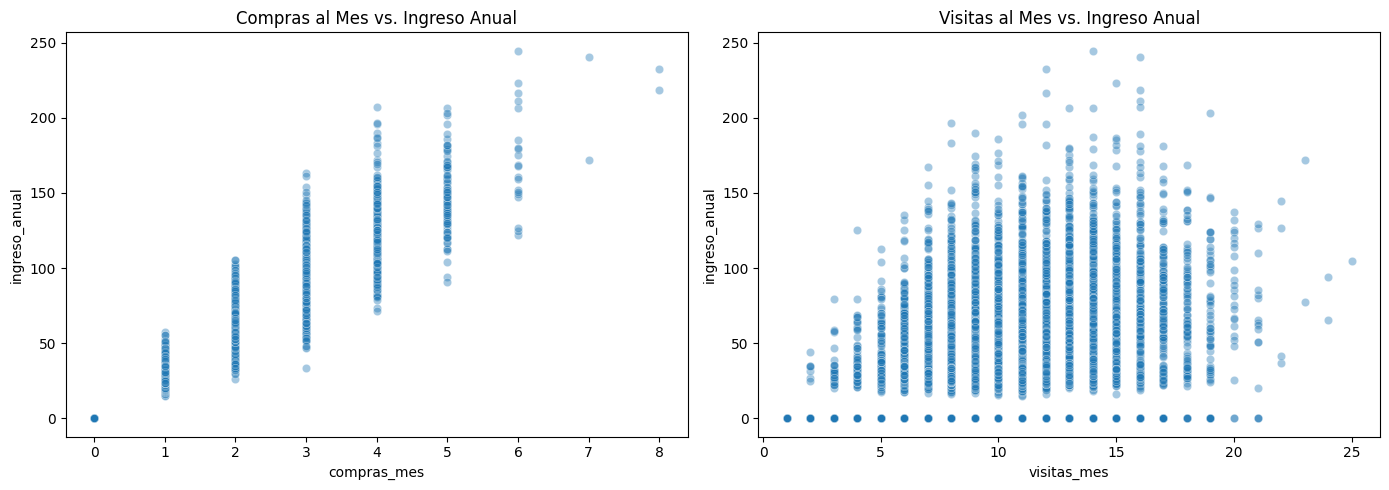

In [17]:
# Scatterplots individuales para los pares clave
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x='compras_mes', y='ingreso_anual', alpha=0.4, ax=axes[0])
axes[0].set_title('Compras al Mes vs. Ingreso Anual')

sns.scatterplot(data=df, x='visitas_mes', y='ingreso_anual', alpha=0.4, ax=axes[1])
axes[1].set_title('Visitas al Mes vs. Ingreso Anual')

plt.tight_layout()
plt.show()

Se requiere filtrar únicamente a las variables `ingreso_anual`, `compras_mes` y `visitas_mes` para evitar saturación visual y que el enfoque sea en las relaciones que el heatmap señaló como las más significativas.

**Observaciones iniciales (Scatterplot):**

**ingreso_anual vs compras_mes**


- **Dirección**: *Positiva*. A medida que aumentan las compras, el ingreso sube de forma escalonada.
- **Disperción**: *Baja*. Los puntos forman "bandas" o columnas verticales muy marcadas.
- **Outliers**: Se observan un par de valores atípicos en la esquina superior derecha (usuarios con 7 u 8 compras que generan un ingreso muy alto que se despega del resto).
- **Colinealidad**: *Alta probabilidad*. Visualmente y con referencia por el 0.97 del heatmap, estas dos variables aportan prácticamente la misma información económica.

**ingreso_anual vs visitas_mes**


- **Dirección**: *Positiva*. Es un poco más débil que la correlación `ingreso_anual` vs `compras_mes`.
- **Disperción**: *Alta*. Los puntos forman una nube gruesa y esparcida en forma de cono, lo que indica que mucha gente visita la plataforma frecuentemente sin garantizar un ingreso alto.
- **Outliers**: Destacan usuarios que con pocas visitas (menores a 5) generan altos ingresos, y viceversa, usuarios con más de 20 visitas cuyo ingreso se queda en la media o por debajo.  
- **Colinealidad**: *Baja*. No hay riesgo de redundancia entre estas dos variables.

# Coeficientes de correlación y evidencia numérica

**🎯 Objetivo:** 

Cuantificar con precisión esstadística la fuerza y dirección de las asociaciones entre variables, aplicando el coeficiente adecuado según su tipo de dato (*Pearson* y *Spearman* ´para numéricas, *Punto-biserial* para binarias y *V de Cramér* para categóricas).

# *Pearson / Spearman*

In [12]:
# Calcular correlación entre variables relevantes
print("--- Correlación de Pearson ---")
print("Ingreso vs Compras", df['ingreso_anual'].corr(df['compras_mes']))
print("Ingreso vs Visitas", df['ingreso_anual'].corr(df['visitas_mes']))
print("Compras vs Visitas", df['compras_mes'].corr(df['visitas_mes']))

--- Correlación de Pearson ---
Ingreso vs Compras 0.9671485435708559
Ingreso vs Visitas 0.3371466432498748
Compras vs Visitas 0.35384389471989774


In [13]:
# Calcular correlación entre variables relevantes
print("--- Correlación de Spearman ---")
print("Ingreso vs Compras", df['ingreso_anual'].corr(df['compras_mes'], method='spearman'))
print("Ingreso vs Visitas", df['ingreso_anual'].corr(df['visitas_mes'], method='spearman'))
print("Compras vs Visitas", df['compras_mes'].corr(df['visitas_mes'], method='spearman'))

--- Correlación de Spearman ---
Ingreso vs Compras 0.9674824920326731
Ingreso vs Visitas 0.3209536973769648
Compras vs Visitas 0.33294292722789276


**Observaciones de correlación:**

**ingreso_anual vs compras_mes**

- **Correlación:** La dirección es *positiva* con una magnitud casi perfecta de 0.97 con ambos métodos.


- **Posible colinealidad:** Existe una gran posibilidad de colinealidad, compras_mes e ingreso_anual, se comportan como si fueran la misma variable en un modelo predictivo.

**ingreso_anual vs visitas_mes**

- **Correlación:** La dirección es *positiva* pero la magnitud es moderada-débil (cerca de 0.34 en Pearson). Por el método Spearman, ese valor se acerca más a 0.32, indicando que aunque más visitas suele acompañar a más ingresos, no es una regla estricta.


- **Posible colinealidad:** *Baja-Nula*. Aportan información distinta al análisis, ya que visitar mucho la plataforma, no garantiza transacciones de alto valor. 

# *Punto-biserial*

In [14]:
# Calcular correlación entre variables relevantes
pb_premium = pointbiserialr(df['miembro_premium'], df['ingreso_anual'])
pb_abandono = pointbiserialr(df['abandono'], df['ingreso_anual'])

print("Punto-biserial (Premium vs Ingreso):", pb_premium.statistic)
print("Punto-biserial (Abandono vs Ingreso):", pb_abandono.statistic)

Punto-biserial (Premium vs Ingreso): 0.09309943961980152
Punto-biserial (Abandono vs Ingreso): -0.0028239340216171995


**Observaciones de Punto-biserial:**

**miembro_premium vs ingreso_anual**

- **Relación:** Dirección positiva con magnitud muy baja (0.09). Esto indica que tener una suscripción premium, no está necesariamente asociado con generar ingresos a la empresa. 

**abandono vs ingreso_anual**

- **Relación:** Dirección negativa (nula), con magnitud prácticamente inexistente. El nivel de ingresos que genera un cliente, no está asociado a si abandona o se queda en la plataforma. 

# *V de Cramér*

In [15]:
# Función para calcular V de Cramér
def cramers_v(dataframe, col_1, col_2):
    tabla = pd.crosstab(dataframe[col_1], dataframe[col_2])
    chi2, _, _, _ = chi2_contingency(tabla)
    n = tabla.values.sum()
    r, c = tabla.shape
    v = np.sqrt(chi2 / (n * (min(r, c) -1)))
    return v

In [18]:
# Aplicar V de Cramér en los 5 pares categóricos/binarios relevantes
pares_cramer = [
    ('region', 'tipo_dispositivo'),
    ('abandono', 'tipo_dispositivo'),
    ('abandono', 'region'),
    ('abandono', 'miembro_premium'),
    ('miembro_premium', 'region')
]

print("--- Resultados de V de Cramér ---")
for col1, col2 in pares_cramer:
    v = cramers_v(df, col1, col2)
    print(f"{col1} vs {col2}: {v:.4f}")

--- Resultados de V de Cramér ---
region vs tipo_dispositivo: 0.0124
abandono vs tipo_dispositivo: 0.0072
abandono vs region: 0.0154
abandono vs miembro_premium: 0.1202
miembro_premium vs region: 0.0126


**Observación de V de Cramér:**

- **'abandono' vs 'miembro_premium':** Es la única asociación relevante entre las variables categóricas/binarias, mostrando una relación ligera pero real entre tener membresía Premium y una menor tasa de abandono **(0.1202)**.


- **'abandono' vs 'tipo_dispositivo/region'** y **'miembro_premium' vs 'region':** Presentan valores cercanos a **0.01**, lo que confirma que son prácticamente independientes.

# 🧩 Interpretación de resultados para el negocio

# Hallazgo 1 — La frecuencia de compras es casi un espejo del ingreso anual

**Evidencia visual:**  
El scatterplot mostró una relación lineal escalonada extremadamente clara y con una dispersión prácticamente nula.

**Evidencia numérica:**   
Los coeficientes de Pearson (0.97) y Spearman (0.97), confirman una correlación positiva idéntica.

**Interpretación:**  
La cantidad de compras al mes y el ingreso anual, crecen de forma simultánea y proporcional, ambas variables representan la misma información económica (colinealidad). 

**No podemos afirmar:**  
Que presionar al usuario a hacer "más transacciones" automáticamente aumente su gasto total. 

**Implicación de negocio:**  
Para futuros modelos predictivos, el equipo de Datos puede utilizar solo una de estas variables para evitar ruido. El crecimiento se debe enfocar en campañas para incentivar la conversión directa (concluir la compra), ya que es el único indicador sólido de valor.

# Hallazgo 2 — El tráfico (visitas) genera interés, pero no garantiza monetización

**Evidencia visual:**  
El scatterplot de visitas vs ingreso, mostró una nube de puntos altamente dispersa en forma de cono, donde destacan usuarios con muchas más visitas pero nulo o muy bajo ingreso.

**Evidencia numérica:**   
El coeficiente de Pearson (0.34) indica una relación positiva pero de magnitud débil o muy poco moderada.

**Interpretación:**  
Aunque los clientes de alto valor suelen visitar la plataforma, la regla no aplica a la inversa: tener un cliente muy activo navegando por la app o web, no asegura que genere ingresos para la empresa.

**No podemos afirmar:**  
Que invertir más presupuesto de marketing para atraer "más tráfico" o generar "más clics", se traducirá instantáneamente en un aumento proporcional de los ingresos anuales.

**Implicación de negocio:**  
Existe un "cuello de botella" o fricción en el embudo de ventas, "el equipo de Crecimiento y Retención" deben investigar a este segmento de "altas visitas / cero compras" para lanzar estrategias de retargeting, optimizar la experiencia de usuario o enviar descuentos personalizados que rompan la barrera de la primera compra.

# Hallazgo 3 — El programa Premium actual no impulsa el valor del cliente 

**Evidencia visual:** El mapa de calor mostró una asociación casi nula con 'ingreso_anual' **(0.09)** pero una ligera correlación negativa con 'abandono' **(-0.12)**.

**Evidencia numérica:** El resultado del coeficiente de V de Cramér en 'abandono' vs 'miembro_premium' es de **0.1202**. 

**Interpretación:** Aunque el Plan Premium no impulsa mayor gasto anual directo, **sí muestra una ligera asociación con una menor tasa de abandono (retención)**, lo que refuerza por qué no debe eliminarse, sino rediseñarse.

**No podemos afirmar:** Que el programa Premium sea un fracaso total o que se deba retirar (de hecho, muestra una ligera señal positiva en retención, aunque faltaría evaluar su impacto en fidelidad a largo plazo).

**Implicación de negocio:** El equipo de Crecimiento, necesita reevaluar los beneficios que ofrece la suscripción Premium. Si el objetivo es que los usuarios gasten más, la oferta actual no los está incentivando a hacerlo. Se podría evaluar implementar descuentos exclusivos, envíos gratis o posibles recompensas por mayor volumen de compra.  

# 🧩 Limitaciones y próximos pasos

**Limitaciones:**

- **Correlación ≠ causalidad:** Este análisis exploratorio indica cuáles variables se mueven juntas (como compras e ingresos), pero no demuestra de forma absoluta que una cause la otra. Se requieren pruebas controladas para confirmar causalidad.
  
  
- **Ausencia de variables temporales:** El dataset evalúa el comportamiento de un solo mes, pero no se sabe con certeza a qué mes se refiere. No es lo mismo el comportamiento de compras y transacciones en los últimos meses del año que durante el segundo trimestre. La estacionalidad es un factor ciego en este análisis.


- **Falta de historial del cliente:** No se cuenta con la fecha de registro, ya que un usuario que visita la app o web por 25 veces sin concretar una compra, podría ser un cliente nuevo que está conociendo o viendo si hay algo distinto a cada rato, mientras que un usuario antiguo ya está familizarizado con el sistema. Colocar a todos los usuarios, sin importar la experiencia dentro de la plataforma, limita mucho la precisión del estudio. 


**Próximos pasos:** 

**Probar segmentación adicional:**

- **Segmentación por antiguedad** - *Dividir a los usuarios* "Nuevos" vs "Retenidos", para ver si los patrones de visita y compra cambian según su etapa.


- **Análisis por cohortes** - Agrupar a los clientes por el mes en el que se registraron para entender su valor a largo plazo.

**Implementar pruebas A/B:**

- **Optimización del embudo de conversión** - Dado el Hallazgo 2, proponer un experimento A/B, enviando un descuento agresivo de primera compra a un grupo de usuarios frecuentes para medir si se logra romper la fricción y convertirlos en clientes que generan más ingreso.

**Profundizar en el programa Premium**

- Ya que los datos duros muestran que el programa Premium no genera más ingresos, el siguiente paso debe ser lanzar una encuesta a los usuarios Premium actuales para entender el porqué lo están consumiendo, por ejemplo: no contar con anuncios o tener envíos gratuitos y/o más rápidos. Así complementar esa información con la que se obtuvo en este análisis.